# INFO 4360: Complex Data Analytics
## Course Project – Phase 2: Development

**Project:** Predicting Financial Product Categories from Consumer Complaint Narratives  
**Group Members:** Rebecca Quaye and Ketty Odero  
**Analysis Path:** Path A – Prediction/Classification


In [3]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
# Load the CFPB complaint dataset
df = pd.read_csv("../Data/cfpb_complaints_sample_2025-08_to_2026-07.csv")

df.head()

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2025-11-03,Mortgage,VA mortgage,Trouble during payment process,Payment process,"b""Summary\n\nShellpoint / XXXX have created a...",Company has responded to the consumer and the ...,"Shellpoint Partners, LLC",TN,37066,Servicemember,Web,2025-11-03,Closed with explanation,Yes,16983019
1,2026-04-27,Debt or credit management,Debt settlement,Didn't provide services promised,NaN,I am filing a complaint against Affirm regardi...,NaN,"Affirm Holdings, Inc",ME,049XX,Older American,Web,2026-04-27,Closed with explanation,Yes,21642170
2,2026-05-19,Debt or credit management,Debt settlement,Confusing or misleading advertising or marketing,NaN,"I received a credit card from "" Best Buy as "" ...",Company has responded to the consumer and the ...,"CITIBANK, N.A.",IL,XXXXX,Older American,Web,2026-07-08,Closed with explanation,Yes,22330665
3,2025-11-29,Debt collection,I do not know,False statements or representation,Attempted to collect wrong amount,I am writing in response to your communication...,NaN,V and H Portfolio,FL,33901,NaN,Web,2025-11-29,Closed with explanation,Yes,17887813
4,2026-02-09,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,I am formally disputing multiple inaccuracies ...,NaN,"EQUIFAX, INC.",CA,90044,NaN,Web,2026-02-09,Closed with non-monetary relief,Yes,19355999


### 1. Data Exploration

We first examine the size and structure of the CFPB complaint dataset.

In [5]:
# Check the dataset size and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumns:")
print(df.columns.tolist())

Number of rows: 5000
Number of columns: 16

Columns:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']


In [6]:
# Check missing values
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values

Tags                            4182
Company public response         3436
Sub-issue                       1398
State                             38
ZIP code                          10
Date received                      0
Product                            0
Sub-product                        0
Issue                              0
Consumer complaint narrative       0
Company                            0
Submitted via                      0
Date sent to company               0
Company response to consumer       0
Timely response?                   0
Complaint ID                       0
dtype: int64

In [7]:
# Summarize missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percent": (df.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]
missing_summary.sort_values("Missing Count", ascending=False)

,Missing Count,Missing Percent
Tags,4182,83.64
Company public response,3436,68.72
Sub-issue,1398,27.96
State,38,0.76
ZIP code,10,0.20


#### Missing Values

The primary variables for this project, **Consumer complaint narrative** and **Product**, have no missing values. This means all 5,000 complaints can be used for the planned text classification analysis. Missing values are concentrated in other fields such as Tags, Company public response, and Sub-issue, which are not the primary input or target variables for our model.

#### Product Distribution

Since **Product** is the target variable for our classification model, we examine how the 5,000 complaints are distributed across the financial product categories.

In [8]:
# Count complaints by product
product_counts = df["Product"].value_counts()

product_counts

Product
Debt or credit management                                  455
Debt collection                                            455
Credit reporting or other personal consumer reports        455
Credit card                                                455
Money transfer, virtual currency, or money service         455
Checking or savings account                                455
Mortgage                                                   454
Payday loan, title loan, personal loan, or advance loan    454
Vehicle loan or lease                                      454
Prepaid card                                               454
Student loan                                               454
Name: count, dtype: int64

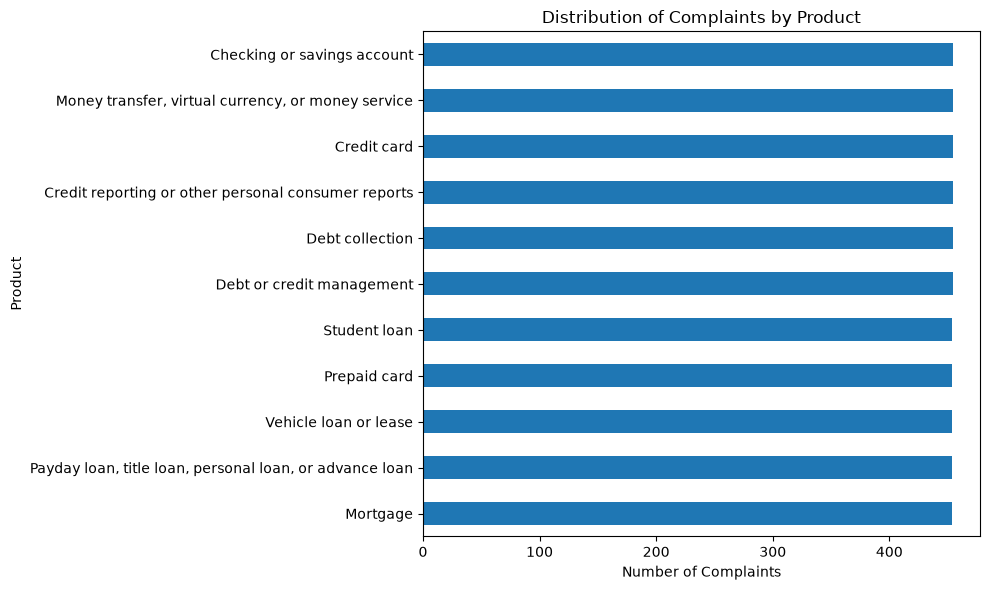

In [9]:
# Plot the product distribution
plt.figure(figsize=(10, 6))
product_counts.sort_values().plot(kind="barh")

plt.title("Distribution of Complaints by Product")
plt.xlabel("Number of Complaints")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

#### Complaint Narrative Length

We examine the length of the consumer complaint narratives to understand how much the amount of text varies across complaints.